In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



df = pd.read_csv("smartcart_customers.csv")

df.head()

df.shape

df.isnull().sum()


ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [ ]:
# Handle Missing Values
df["Income"] = df["Income"].fillna(df["Income"].median())


df.head()



In [ ]:
# Feature Engineering

df["Age"] = 2026-df["Year_Birth"]

In [ ]:


# Customer Joining Date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference_date = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days


In [ ]:
# Spending

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"]  + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]


In [ ]:
# Children
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]


In [ ]:
# Education

df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate", "PhD": "Postgraduate"
})


In [ ]:
# Marital Status

df["Living_With"] = df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone", "Divorced": "Alone",
    "Widow": "Alone", "Absurd": "Alone", "YOLO": "Alone"
})


In [ ]:
# Drop Columns
df.head()

cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns=cols_to_drop)


df_cleaned.shape


df_cleaned.head()



cols = ["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]

In [ ]:
# HeatMap


corr = df_cleaned.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size": 6},
    cmap="coolwarm"
)


In [ ]:
# Encoding

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])



enc_df = pd.DataFrame(enc_cols.toarray(), columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)


df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df], axis=1)


df_encoded.shape


df_encoded.head()

In [ ]:

from sklearn.preprocessing import StandardScaler


X = df_encoded

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


from sklearn.decomposition import PCA


pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

In [42]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=4)
labels_agg = agg.fit_predict(X_pca)

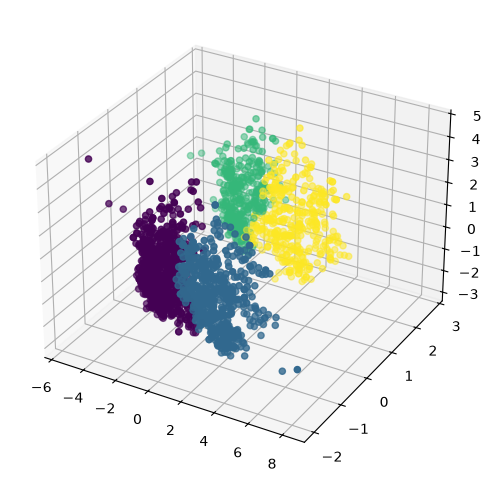

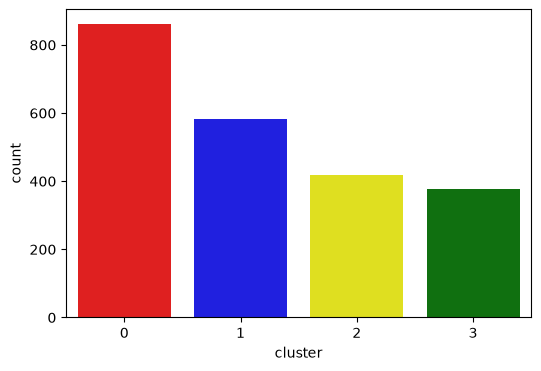

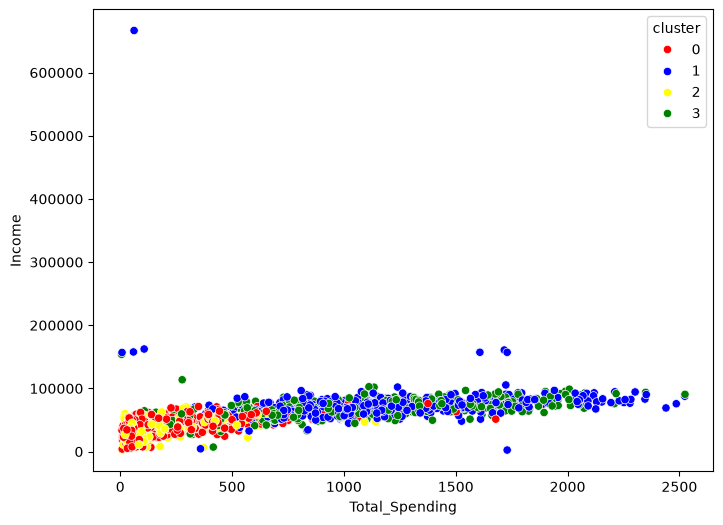

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        38591.904762  49.112660           2.614402         2.973287   
1        72606.704974  48.864494           1.996569         5.727273   
2        36539.742823  47.717703           2.583732         2.622010   
3        69264.850529  51.018519           1.886243         5.701058   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.854820           3.929152           6.456446  0.009292   
1                   5.289880           8.574614           3.648370  0.008576   
2                   0.803828           3.543062           6.631579  0.014354   
3                   4.780423           8.219577           3.838624  0.005291   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
cluster         

In [43]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels_agg)
plt.show()   # finishes the 3D figure

X["cluster"] = labels_agg

pal = ["red", "blue", "yellow", "green"]

plt.figure(figsize=(6, 4))
sns.countplot(x=X["cluster"], palette=pal, hue=X["cluster"], legend=False)
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X["Total_Spending"], y=X["Income"], hue=X["cluster"], palette=pal)
plt.show()

cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

